In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader

c:\Users\user\Documents\Disco duro\Univerisidad\Machine Learning\ML_202604_Santiago_Lopez_F\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
hfdataset= HFDatasetLoader(dataset_name="aptologia/precios-arriendo-colombia", split="train", filename="datos/precios-arriendo-colombia_clasificacion.csv")

In [3]:
df_clasificacion_crudo = hfdataset.load()
df_clasificacion_crudo.head(2)

,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841


# Comvierto mi database para poder tener informacion de texto agregando una columna que me indique si el valor de la propiedad entra en una categoria de alto medio o bajo.

In [4]:
import numpy as np
import pandas as pd

def crear_texto_propiedad(row):
  tokens = []

  # Categóricas directas
  tokens.append(f"ciudad_{row['ciudad_id']}")
  tokens.append(f"barrio_{str(row['barrio']).lower().replace(' ', '_')}")

  # Rango de precios basado en la mediana
  mediana = row["mediana"]
  if mediana >= 7000000:
    tokens.append("precio_alto_gama_alta")
  elif mediana >= 4500000:
    tokens.append("precio_medio")
  else:
    tokens.append("precio_economico")

  # Proporción de equipamiento (Parqueadero y Teléfono)
  if row["avisos"] > 0:
    prop_parq = row["con_parqueadero"] / row["avisos"]
    prop_tel = row["con_telefono"] / row["avisos"]

    if prop_parq > 0.7:
      tokens.append("alto_parqueadero")
    if prop_tel > 0.5:
      tokens.append("alta_conectividad_telefono")

  # Nivel de volumen de oferta
  if row["avisos"] > 10000:
    tokens.append("alta_oferta_avisos")

  return " ".join(tokens)

# Aplicar la transformación a tu dataframe
dfc_clasificacion_crudo = df_clasificacion_crudo.copy()
dfc_clasificacion_crudo["text"] = dfc_clasificacion_crudo.apply(crear_texto_propiedad, axis=1)

In [5]:
dfc_clasificacion_crudo.head(2)


,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono,text
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599,ciudad_medellin barrio_el_poblado precio_medio...
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841,ciudad_medellin barrio_poblado precio_medio al...


## Clasificacion

In [6]:
pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [7]:
%pip install --upgrade matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ---------------- ----------------------- 3.9/9.3 MB 16.8 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 24.2 MB/s  0:00:00
  Attempting uninstall: matplotlib
    Found existing installation: matplotlib 3.9.4
    Uninstalling matplotlib-3.9.4:
      Successfully uninstalled matplotlib-3.9.4
Note: you may need to restart the kernel to use updated packages.


In [8]:
import matplotlib
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, precision_score, recall_score

from clases_po import ClasificadorTexto   # versión con alias de columnas y palabras_clave()

CLASES = ["alto", "medio", "economico"]
COLORES = {"medio": "#1f6fe5", "alto": "#f2661b", "economico": "#e5384b"}
UMBRAL_COSTOSO = 0.5                                  # ajústalo después de ver el bloque 1
CACHE_COSTOSO = Path("datos/precios-arriendo-colombia.csv")  # el modelo de COSTOSIDAD corre una sola vez
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = dfc_clasificacion_crudo.copy()
df.loc[:, "text"] = df["text"].fillna("").astype(str).str.strip()

In [9]:
dfc_clasificacion_crudo.head(5)

,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono,text
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599,ciudad_medellin barrio_el_poblado precio_medio...
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841,ciudad_medellin barrio_poblado precio_medio al...
2,2026-10-05,medellin,Medellín,Laureles,5780,3300000,4200000,5300000,4283,2169,ciudad_medellin barrio_laureles precio_economi...
3,2026-10-05,medellin,Medellín,Castropol,2730,4200000,5350000,7000000,2286,1547,ciudad_medellin barrio_castropol precio_medio ...
4,2026-10-05,medellin,Medellín,El Tesoro,2471,5800000,7700000,11500000,2167,1278,ciudad_medellin barrio_el_tesoro precio_alto_g...


In [10]:
%pip install torch

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 1.3/124.1 MB 5.6 MB/s eta 0:00:22
   -- ------------------------------------- 8.1/124.1 MB 20.2 MB/s eta 0:00:06
   ------ --------------------------------- 18.9/124.1 MB 31.4 MB/s eta 0:00:04
   ---------- ----------------------------- 33.0/124.1 MB 40.4 MB/s eta 0:00:03
   -------------- ------------------------- 46.4/124.1 MB 44.8 MB/s eta 0:00:02
   --------------------- ------------------ 65.5/124.1 MB 53.6 MB/s eta 0:00:02
   --------------------------- ------------ 83.9/124.1 MB 58.8 MB/s eta 0:00:01
   ------------------------------- ------- 100.7/124.1 MB 61.8 MB/s eta 0:00:01
   ------------------------------------- - 118.8/124.1 MB 64.3 MB/s eta 0:00:01
   --------------------------------------  124.0/124.1 MB 65.5 MB/s eta 0

In [11]:
%pip install transformers

   ---------------------------------------- 0.0/12.8 MB ? eta -:--:--
   -------------------- ------------------- 6.6/12.8 MB 44.9 MB/s eta 0:00:01
   ---------------------------------------- 12.8/12.8 MB 53.8 MB/s  0:00:00
   ---------------------------------------- 0.0/2.9 MB ? eta -:--:--
   ---------------------------------------- 2.9/2.9 MB 55.5 MB/s  0:00:00

   ---- -----------------------------------  1/10 [safetensors]
   -------- -------------------------------  2/10 [regex]
   ---------------- -----------------------  4/10 [annotated-doc]
   -------------------- -------------------  5/10 [markdown-it-py]
   -------------------- -------------------  5/10 [markdown-it-py]
   -------------------- -------------------  5/10 [markdown-it-py]
   -------------------- -------------------  5/10 [markdown-it-py]
   -------------------- -------------------  5/10 [markdown-it-py]
   ------------------------ ---------------  6/10 [rich]
   ------------------------ ---------------  6/10 [r

In [12]:
df.head(5)

,fecha,ciudad_id,ciudad,barrio,avisos,p25,mediana,p75,con_parqueadero,con_telefono,text
0,2026-10-05,medellin,Medellín,El Poblado,17124,4400000,5700000,7700000,15907,6599,ciudad_medellin barrio_el_poblado precio_medio...
1,2026-10-05,medellin,Medellín,Poblado,7593,4100000,5650000,8000000,6509,841,ciudad_medellin barrio_poblado precio_medio al...
2,2026-10-05,medellin,Medellín,Laureles,5780,3300000,4200000,5300000,4283,2169,ciudad_medellin barrio_laureles precio_economi...
3,2026-10-05,medellin,Medellín,Castropol,2730,4200000,5350000,7000000,2286,1547,ciudad_medellin barrio_castropol precio_medio ...
4,2026-10-05,medellin,Medellín,El Tesoro,2471,5800000,7700000,11500000,2167,1278,ciudad_medellin barrio_el_tesoro precio_alto_g...


Entrenando modelo de estimación de costos...
Guardado en datos\precios-arriendo-v2.csv

--- Sensibilidad del umbral para clasificar como COSTOSO/ALTO ---
Umbral 0.3:    85 registros serían clasificados como 'alto'
Umbral 0.5:    85 registros serían clasificados como 'alto'
Umbral 0.7:    85 registros serían clasificados como 'alto'
Umbral 0.9:    79 registros serían clasificados como 'alto'


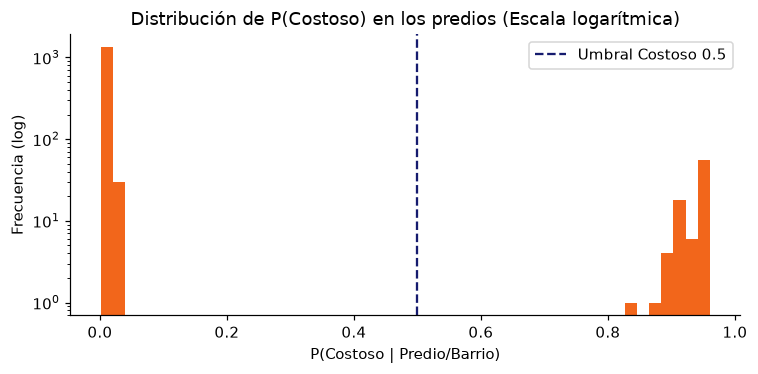


--- Conteo de Etiquetas Finales ---
etiqueta
economico    1199
medio         176
alto           85
Name: count, dtype: int64

Ejemplos marcados con categoría ALTO:
     ciudad              barrio   mediana  p_costoso  \
508  Bogotá               Chico   7500000   0.960823   
510  Bogotá     Chico Reservado  10000000   0.960823   
512  Bogotá         Los Rosales  10500000   0.960823   
520  Bogotá            El Chico   7000000   0.960823   
532  Bogotá         La Carolina   8250000   0.960823   
537  Bogotá           El Virrey   8000000   0.960823   
538  Bogotá             Cabrera  15000000   0.960823   
547  Bogotá  Santa Barbara Alta  15000000   0.960823   

                                                                               text  
508               ciudad_bogota barrio_chico precio_alto_gama_alta alto_parqueadero  
510     ciudad_bogota barrio_chico_reservado precio_alto_gama_alta alto_parqueadero  
512         ciudad_bogota barrio_los_rosales precio_alto_gama_alta alto_

In [13]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression

# 1. Definición de Constantes
CLASES = ["alto", "medio", "economico"]
COLORES = {"medio": "#1f6fe5", "alto": "#f2661b", "economico": "#e5384b"}
UMBRAL_COSTOSO = 0.5 

# SOLUCIÓN 1: Cambiamos el nombre del archivo para ignorar el CSV corrupto anterior
CACHE_COSTOSO = Path("datos/precios-arriendo-v2.csv")

# Aislamiento total del DataFrame
df = df.copy()

if "predio_id" not in df.columns:
    df.loc[:, "predio_id"] = df.index

# FIX LÍNEA 24: Asignación segura con .loc para evitar FutureWarning
df.loc[:, "text"] = df["text"].fillna("").astype(str)

# 2. Lógica del Modelo y Caché
if CACHE_COSTOSO.exists():
    prob_df = pd.read_csv(CACHE_COSTOSO)
    print("Probabilidades de precio alto leídas de", CACHE_COSTOSO)
else:
    print("Entrenando modelo de estimación de costos...")
    
    y_binary = (df["mediana"] >= 7000000).astype(int)
    
    vec = CountVectorizer()
    X = vec.fit_transform(df["text"])
    
    clf = LogisticRegression(max_iter=1000)
    clf.fit(X, y_binary)
    
    prob_costoso = clf.predict_proba(X)[:, 1]
    
    prob_df = pd.DataFrame(
        {"predio_id": df["predio_id"].to_numpy(), "p_costoso": prob_costoso}
    )
    
    CACHE_COSTOSO.parent.mkdir(parents=True, exist_ok=True)
    prob_df.to_csv(CACHE_COSTOSO, index=False)
    print("Guardado en", CACHE_COSTOSO)

# 3. Integración de resultados
df = df.drop(columns=["p_costoso"], errors="ignore").merge(
    prob_df, on="predio_id", how="left"
)
# FIX LÍNEA 55: Asignación segura con .loc para evitar FutureWarning
df.loc[:, "p_costoso"] = df["p_costoso"].fillna(0.0)

# 4. Evaluación de Umbrales
print("\n--- Sensibilidad del umbral para clasificar como COSTOSO/ALTO ---")
for u in [0.3, 0.5, 0.7, 0.9]:
    total = (df["p_costoso"] >= u).sum()
    print(f"Umbral {u}: {total:>5} registros serían clasificados como 'alto'")

# 5. Histograma de Probabilidades
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(df["p_costoso"], bins=50, color=COLORES["alto"])
ax.axvline(
    UMBRAL_COSTOSO,
    color="#151b6e",
    ls="--",
    label=f"Umbral Costoso {UMBRAL_COSTOSO}",
)
ax.set_yscale("log")
ax.set_title("Distribución de P(Costoso) en los predios (Escala logarítmica)")
ax.set_xlabel("P(Costoso | Predio/Barrio)")
ax.set_ylabel("Frecuencia (log)")
ax.legend()
plt.tight_layout()
plt.show()

# 6. Asignación de Etiquetas Definitivas
condiciones = [
    df["p_costoso"] >= UMBRAL_COSTOSO, 
    (df["mediana"] < 4500000)
]
elecciones = ["alto", "economico"]
df.loc[:, "etiqueta"] = np.select(condiciones, elecciones, default="medio")

print("\n--- Conteo de Etiquetas Finales ---")
print(df["etiqueta"].value_counts())

# 7. Muestra de Predios clasificados como 'Alto'
print("\nEjemplos marcados con categoría ALTO:")
pd.set_option("display.max_colwidth", 160)
columnas_mostrar = ["ciudad", "barrio", "mediana", "p_costoso", "text"]
print(df[df["etiqueta"] == "alto"].nlargest(8, "p_costoso")[columnas_mostrar])

In [14]:
print("--- 2 · Estructura y calidad -> escena 6 ---")
print("Forma (filas, columnas):", df.shape)
print("\n--- Información del DataFrame ---")
df.info()

print("\n--- Valores faltantes por columna ---")
print(df.isna().sum())

print("\n--- Análisis de duplicados y vacíos ---")
# Verifica si hay combinaciones de texto idénticas (mismo barrio, ciudad y características)
print("Textos descriptivos duplicados exactos:", df.duplicated(subset=["text"]).sum())

# Verifica si algún registro quedó con la columna 'text' completamente vacía
print("Registros con texto vacío:", (df["text"].str.strip() == "").sum())

# Reemplazamos la revisión de 'message' por una revisión de 'barrio' (columna clave en tus datos)
print("Registros sin barrio especificado (nulos o en blanco):", 
      df["barrio"].isna().sum() + (df["barrio"].astype(str).str.strip() == "").sum())

--- 2 · Estructura y calidad -> escena 6 ---
Forma (filas, columnas): (1460, 14)

--- Información del DataFrame ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   fecha            1460 non-null   object 
 1   ciudad_id        1460 non-null   object 
 2   ciudad           1460 non-null   object 
 3   barrio           1460 non-null   object 
 4   avisos           1460 non-null   int64  
 5   p25              1460 non-null   int64  
 6   mediana          1460 non-null   int64  
 7   p75              1460 non-null   int64  
 8   con_parqueadero  1460 non-null   int64  
 9   con_telefono     1460 non-null   int64  
 10  text             1460 non-null   object 
 11  predio_id        1460 non-null   int64  
 12  p_costoso        1460 non-null   float64
 13  etiqueta         1460 non-null   object 
dtypes: float64(1), int64(7), object(6)
m

--- 3 · Balance de las tres clases -> escena 10 ---
           predios      %
etiqueta                 
alto            85   5.82
medio          176  12.05
economico     1199  82.12


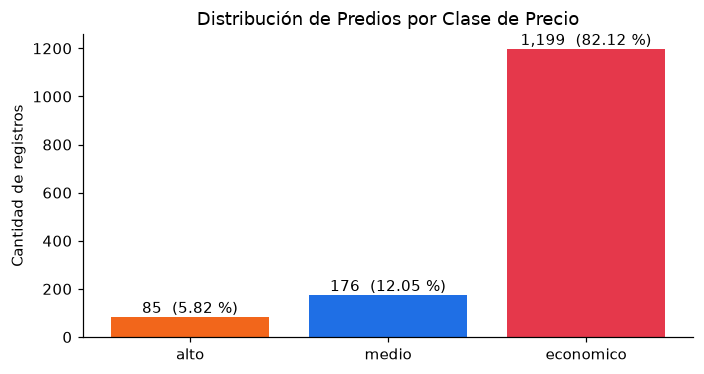

Si el modelo perezoso responde siempre 'economico': exactitud = 82.1%, predios de valor 'alto' detectados = 0 de 85


In [15]:
print("--- 3 · Balance de las tres clases -> escena 10 ---")

# Cálculo de frecuencias y porcentajes
conteo = df["etiqueta"].value_counts().reindex(CLASES).fillna(0).astype(int)
porc = (conteo / conteo.sum() * 100).round(2)
print(pd.DataFrame({"predios": conteo, "%": porc}))

# Gráfico de barras
fig, ax = plt.subplots(figsize=(6.5, 3.5))
barras = ax.bar(conteo.index, conteo.values, color=[COLORES.get(c, "gray") for c in conteo.index])
ax.bar_label(barras, labels=[f"{v:,}  ({p} %)" for v, p in zip(conteo.values, porc.values)])
ax.set_title("Distribución de Predios por Clase de Precio")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

# Pere, el modelo perezoso (Baseline): siempre predice la clase mayoritaria
mayoritaria = conteo.idxmax()
print(f"Si el modelo perezoso responde siempre '{mayoritaria}': "
      f"exactitud = {conteo.max() / conteo.sum():.1%}, "
      f"predios de valor 'alto' detectados = 0 de {conteo.get('alto', 0)}")

 Longitud de del mensaje por clase -> escenas 5 y 6

--- 4 · Longitud del texto descriptivo por clase -> escenas 5 y 6 ---
            count  mean  std  min  25%  50%  75%  max
etiqueta                                             
alto         85.0   4.0  0.5  3.0  4.0  4.0  4.0  5.0
medio       176.0   4.2  0.7  3.0  4.0  4.0  5.0  5.0
economico  1199.0   3.6  0.7  3.0  3.0  3.0  4.0  5.0


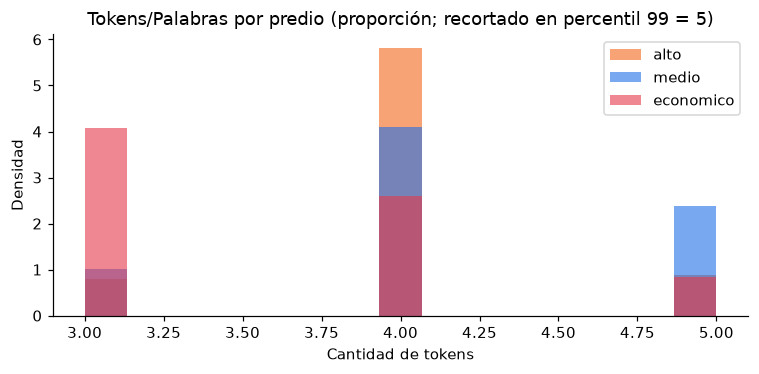

In [16]:
print("--- 4 · Longitud del texto descriptivo por clase -> escenas 5 y 6 ---")

# Solución al warning: aislar el DataFrame para trabajar de forma segura
df = df.copy()

# Contar la cantidad de palabras (tokens) por registro usando .loc
df.loc[:, "palabras"] = df["text"].str.split().str.len()

# Mostrar estadísticas descriptivas de la longitud por categoría
print(df.groupby("etiqueta")["palabras"].describe().reindex(CLASES).round(1))

# Filtrar outliers usando el percentil 99
tope = df["palabras"].quantile(0.99)

fig, ax = plt.subplots(figsize=(7, 3.5))
for clase in CLASES:
    grupo = df.loc[df["etiqueta"] == clase, "palabras"].clip(upper=tope)
    ax.hist(grupo, bins=15, alpha=.6, density=True, label=clase, color=COLORES.get(clase, "gray"))

ax.set_title(f"Tokens/Palabras por predio (proporción; recortado en percentil 99 = {tope:.0f})")
ax.set_xlabel("Cantidad de tokens")
ax.set_ylabel("Densidad")
ax.legend()
plt.tight_layout()
plt.show()


5 · Fechas por clase -> escena 7 (radiografía): no usar la fecha como característica

--- 5 · Fechas por clase -> escena 7 (radiografía) ---
etiqueta  alto  medio  economico
anio                            
2026        82    154        764


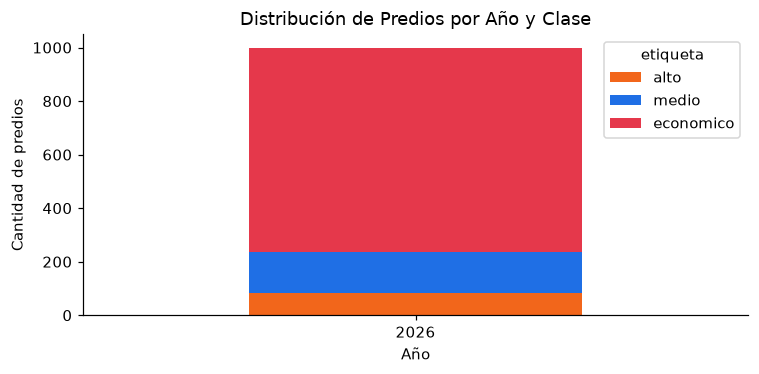

In [ ]:
# Convertir la columna 'fecha' a formato datetime y extraer el año
df["anio"] = pd.to_datetime(df["fecha"], errors="coerce").dt.year

# Crear la tabla cruzada (crosstab)
tabla_anios = pd.crosstab(df["anio"], df["etiqueta"]).reindex(columns=CLASES, fill_value=0)
print(tabla_anios)

# Generar el gráfico de barras apiladas
tabla_anios.plot(
    kind="bar", 
    stacked=True, 
    figsize=(7, 3.5),
    color=[COLORES.get(c, "gray") for c in CLASES], 
    title="Distribución de Predios por Año y Clase"
)

plt.ylabel("Cantidad de predios")
plt.xlabel("Año")
plt.xticks(rotation=0)  
plt.tight_layout()
plt.show()

6 · Palabras más frecuentes por clase -> escena 12 (TF-IDF)

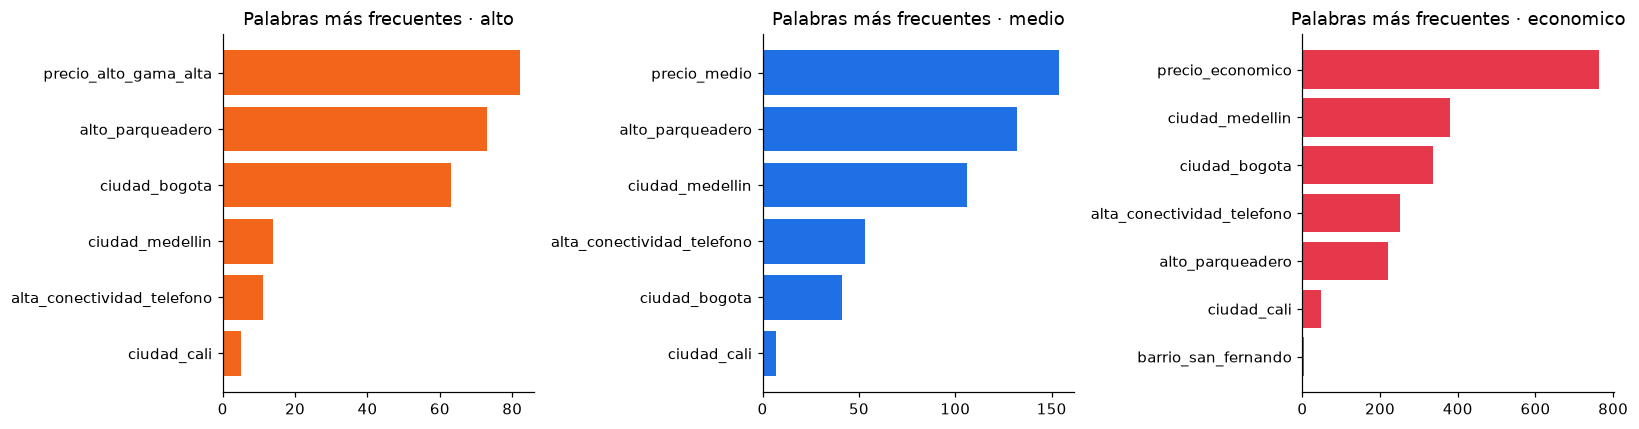

In [19]:
def top_palabras(textos, n=15):
    cv = CountVectorizer(stop_words="english", min_df=3)
    m = cv.fit_transform(textos)
    suma = np.asarray(m.sum(axis=0)).ravel()
    orden = suma.argsort()[::-1][:n]
    return pd.Series(suma[orden], index=cv.get_feature_names_out()[orden])

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for eje, clase in zip(ejes, CLASES):
    top = top_palabras(df.loc[df["etiqueta"] == clase, "text"])
    eje.barh(top.index[::-1], top.values[::-1], color=COLORES[clase])
    eje.set_title(f"Palabras más frecuentes · {clase}")
plt.tight_layout()
plt.show()

7 · Primer experimento con la clase (Naive Bayes, tres clases) -> escenas 13 y 15

In [20]:
# Instanciamos el clasificador usando las columnas que ya preparamos
nb = ClasificadorTexto(
    modelo=MultinomialNB(), 
    columna_texto="text", 
    columna_objetivo="etiqueta"
)

# Ejecutamos el pipeline de entrenamiento y evaluación sobre tu dataset
r_nb = nb.ejecutar(df)

# Mostramos las métricas de rendimiento (Precisión, Recall, F1, etc.) por clase
print("Métricas de evaluación por clase:")
print(r_nb["metricas"]["por_clase"].round(4))

[ejecutar][1/6] cargar_datos (MultinomialNB)
[ejecutar][2/6] preparar_datos
[preparar_datos] 1000 textos válidos; 0 filas eliminadas; clases: {'economico': 764, 'medio': 154, 'alto': 82}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=800; prueba=200; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] TfidfVectorizer(1, 1) -> MultinomialNB
[ejecutar][5/6] entrenar
[entrenar] 800 textos; modelo guardado en modelos\20261025_142239_435256_MultinomialNB.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=0.9650; F1 macro=0.9197; F1 ponderado=0.9629
              precision    recall  f1-score   support

        alto     1.0000    0.6875    0.8148        16
   economico     0.9563    1.0000    0.9776       153
       medio     1.0000    0.9355    0.9667        31

    accuracy                         0.9650       200
   macro avg     0.9854    0.8743    0.9197       200
weighted avg     0.9665    0.9650    0.9629       200

                pred alto  pr

8 · Palabras que delatan cada clase -> escena 14b

In [ ]:
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

# 1. Vectorización y entrenamiento (recreado de forma nativa)
vec = CountVectorizer(min_df=1)
X_vec = vec.fit_transform(df["text"].fillna("").astype(str))
y_vec = df["etiqueta"]

modelo_nb = MultinomialNB()
modelo_nb.fit(X_vec, y_vec)

# 2. Obtener el vocabulario (tokens de ciudad, barrio, precios, etc.)
nombres_atributos = np.array(vec.get_feature_names_out())

# 3. Extraer los 15 atributos con mayor probabilidad para cada clase
for i, clase in enumerate(modelo_nb.classes_):
    # .feature_log_prob_ indica qué tanto peso/probabilidad tiene una palabra en esta clase
    probabilidades = modelo_nb.feature_log_prob_[i]
    
    # Ordenamos de mayor a menor y extraemos los 15 primeros índices
    top_indices = probabilidades.argsort()[::-1][:15]
    top_palabras = nombres_atributos[top_indices]
    
    print(f"\nAtributos que delatan a la clase -> {clase.upper()}:")
    for idx, palabra in enumerate(top_palabras, 1):
        print(f"  {idx}. {palabra}")

--- 8 · Palabras (atributos) que delatan cada clase -> escena 14b ---

Atributos que delatan a la clase -> ALTO:
  1. precio_alto_gama_alta
  2. alto_parqueadero
  3. ciudad_bogota
  4. ciudad_medellin
  5. alta_conectividad_telefono
  6. ciudad_cali
  7. barrio_san_lucas
  8. barrio_los_rosales_norte
  9. barrio_montearroyo
  10. barrio_urbanizacion_arcoiris
  11. barrio_sierras_del_moral
  12. barrio_norte
  13. barrio_los_rosales_emaus
  14. barrio_la_tomatera
  15. barrio_normandia

Atributos que delatan a la clase -> ECONOMICO:
  1. precio_economico
  2. ciudad_medellin
  3. ciudad_bogota
  4. alta_conectividad_telefono
  5. alto_parqueadero
  6. ciudad_cali
  7. barrio_san_fernando
  8. barrio_san_rafael
  9. barrio_a_s_d
  10. barrio_primavera
  11. barrio_san_marcos
  12. barrio_rionegro
  13. barrio_antonio_narino
  14. barrio_santa_teresita
  15. barrio_zona_industrial

Atributos que delatan a la clase -> MEDIO:
  1. precio_medio
  2. alto_parqueadero
  3. ciudad_medellin
  4

9 · Matriz de confusión 3 × 3 -> escenas 15 a 21

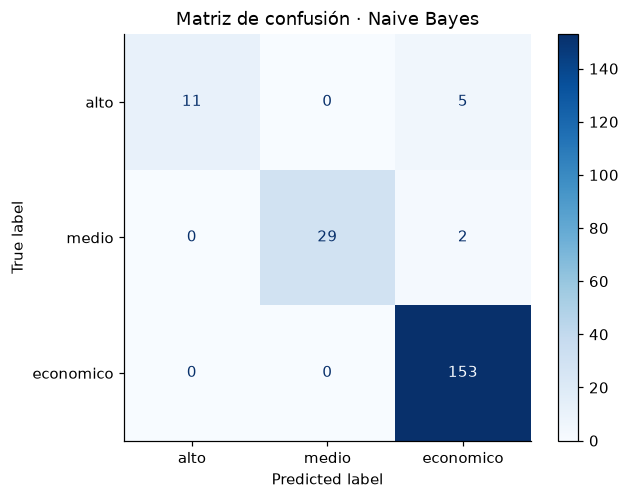

In [23]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from IPython.display import Image, display

# Generar la matriz usando los resultados de tu clase ClasificadorTexto
ConfusionMatrixDisplay.from_predictions(
    nb.y_test, 
    r_nb["predicciones"], 
    labels=CLASES,
    cmap="Blues", 
    values_format=",d"
)

plt.title("Matriz de confusión · Naive Bayes")

# Guardar y renderizar como imagen estática
ruta_matriz = "matriz_confusion_nb.png"
plt.savefig(ruta_matriz, bbox_inches="tight")
plt.close() # Libera la memoria

# Mostrar en el notebook
display(Image(filename=ruta_matriz))

10 · Ejemplos de errores -> discusión en clase

In [24]:
# 1. Crear el DataFrame con los resultados de la prueba
errores = pd.DataFrame({
    "texto": nb.X_test.to_numpy(), 
    "real": nb.y_test.to_numpy(), 
    "predicho": r_nb["predicciones"]
})

# 2. Filtrar dejando únicamente las predicciones incorrectas
errores = errores[errores["real"] != errores["predicho"]]
print("Resumen de errores por tipo:\n", errores.groupby(["real", "predicho"]).size(), "\n")

# 3. Pares de confusión que nos interesa inspeccionar en bienes raíces
pares_a_revisar = [
    ("alto", "economico"), # Predio muy costoso que el modelo creyó que era barato
    ("economico", "alto"), # Predio muy barato que el modelo creyó que era costoso
    ("alto", "medio"),     # Confusión de límite inferior
    ("medio", "alto"),     # Confusión de límite superior
]

for real, pred in pares_a_revisar:
    sub = errores[(errores["real"] == real) & (errores["predicho"] == pred)]
    print(f"--- Real: {real.upper()} → Predicho: {pred.upper()} ({len(sub)} casos)")
    
    if not sub.empty:
        # Mostramos los primeros 3 ejemplos, mostrando hasta 150 caracteres del texto descriptivo
        print(sub["texto"].str[:150].head(3).to_string(), "\n")
    else:
        print("  Ningún error detectado de este tipo.\n")

Resumen de errores por tipo:
 real   predicho 
alto   economico    5
medio  economico    2
dtype: int64 

--- Real: ALTO → Predicho: ECONOMICO (5 casos)
117               ciudad_bogota barrio_rosales_bella_vista precio_alto_gama_alta alta_conectividad_telefono
128      ciudad_medellin barrio_san_lucas precio_alto_gama_alta alto_parqueadero alta_conectividad_telefono
145    ciudad_bogota barrio_cabrera_chico precio_alto_gama_alta alto_parqueadero alta_conectividad_telefono 

--- Real: ECONOMICO → Predicho: ALTO (0 casos)
  Ningún error detectado de este tipo.

--- Real: ALTO → Predicho: MEDIO (0 casos)
  Ningún error detectado de este tipo.

--- Real: MEDIO → Predicho: ALTO (0 casos)
  Ningún error detectado de este tipo.



11 · Cambiar de modelo: regresión logística balanceada -> escenas 22 a 24

[ejecutar][1/6] cargar_datos (LogisticRegression)
[ejecutar][2/6] preparar_datos
[preparar_datos] 1000 textos válidos; 0 filas eliminadas; clases: {'economico': 764, 'medio': 154, 'alto': 82}.
[ejecutar][3/6] dividir_datos
[dividir_datos] stratify=y; entrenamiento=800; prueba=200; random_state=42.
[ejecutar][4/6] construir_modelo
[construir_modelo] TfidfVectorizer(1, 1) -> LogisticRegression
[ejecutar][5/6] entrenar
[entrenar] 800 textos; modelo guardado en modelos\20261025_143112_924981_LogisticRegression.pkl
[ejecutar][6/6] evaluar
[evaluar] exactitud=1.0000; F1 macro=1.0000; F1 ponderado=1.0000
              precision    recall  f1-score   support

        alto     1.0000    1.0000    1.0000        16
   economico     1.0000    1.0000    1.0000       153
       medio     1.0000    1.0000    1.0000        31

    accuracy                         1.0000       200
   macro avg     1.0000    1.0000    1.0000       200
weighted avg     1.0000    1.0000    1.0000       200

              

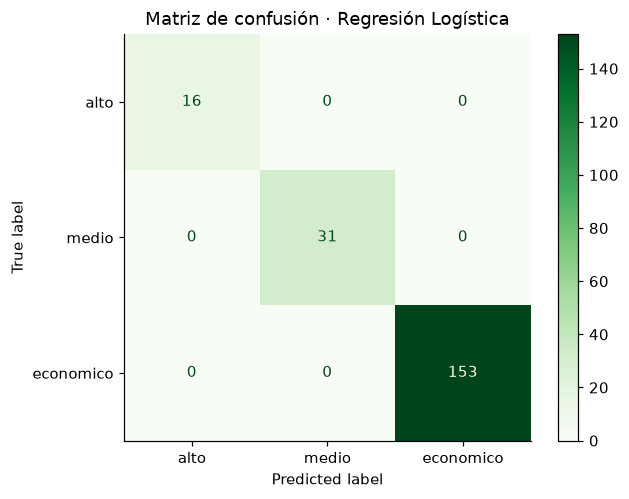


Comparación de rendimiento entre modelos:
                     exactitud  F1 macro  F1 ponderado  precisión alto  \
Naive Bayes              0.965    0.9197        0.9629             1.0   
Regresión Logística      1.000    1.0000        1.0000             1.0   

                     recall alto  F1 alto  F1 medio  F1 economico  
Naive Bayes               0.6875   0.8148    0.9667        0.9776  
Regresión Logística       1.0000   1.0000    1.0000        1.0000  


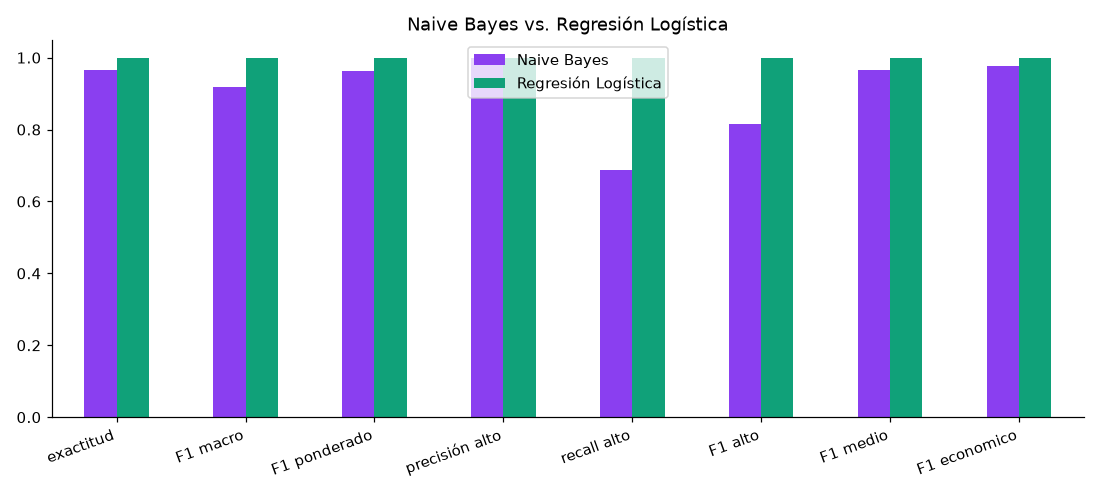

In [25]:
# 1. Entrenamiento de Regresión Logística
lr = ClasificadorTexto(
    modelo=LogisticRegression(class_weight="balanced", max_iter=1000),
    columna_texto="text", 
    columna_objetivo="etiqueta"
)
r_lr = lr.ejecutar(df)

# 2. Matriz de confusión para Regresión Logística
ConfusionMatrixDisplay.from_predictions(
    lr.y_test, 
    r_lr["predicciones"], 
    labels=CLASES,
    cmap="Greens", 
    values_format=",d"
)
plt.title("Matriz de confusión · Regresión Logística")
ruta_cm_lr = "matriz_confusion_lr.png"
plt.savefig(ruta_cm_lr, bbox_inches="tight")
plt.close()
display(Image(filename=ruta_cm_lr))

# 3. Función de resumen adaptada a las clases inmobiliarias
def resumen(m):
    pc = m["por_clase"]
    return {
        "exactitud": m["exactitud"], 
        "F1 macro": m["f1_macro"], 
        "F1 ponderado": m["f1_ponderado"],
        "precisión alto": pc.loc["alto", "precision"], 
        "recall alto": pc.loc["alto", "recall"],
        "F1 alto": pc.loc["alto", "f1"], 
        "F1 medio": pc.loc["medio", "f1"], 
        "F1 economico": pc.loc["economico", "f1"]
    }

# 4. Tabla de comparación
comparacion = pd.DataFrame({
    "Naive Bayes": resumen(r_nb["metricas"]),
    "Regresión Logística": resumen(r_lr["metricas"])
}).T.round(4)

print("\nComparación de rendimiento entre modelos:")
print(comparacion)

# 5. Gráfico de barras de comparación
comparacion.T.plot(
    kind="bar", 
    figsize=(10, 4.5), 
    ylim=(0, 1.05),
    color=["#8a3ff0", "#10a179"], 
    title="Naive Bayes vs. Regresión Logística"
)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
ruta_comp = "comparacion_modelos.png"
plt.savefig(ruta_comp)
plt.close()
display(Image(filename=ruta_comp))

12 · El umbral de tóxico -> escena 25 (el umbral también decide)

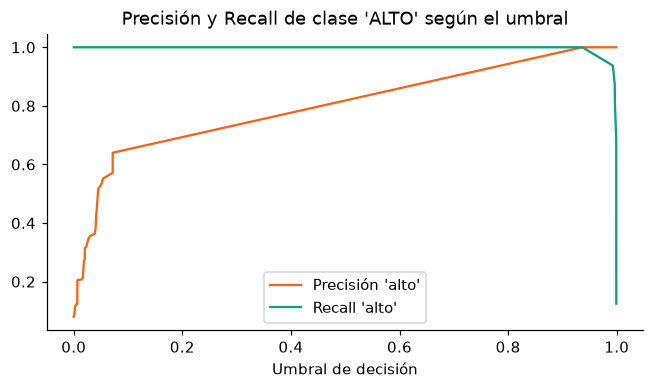


Predios realmente 'ALTO' en prueba: 16
   umbral  precisión alto  recall alto  altos detectados  \
0     0.2             1.0          1.0                16   
1     0.3             1.0          1.0                16   
2     0.5             1.0          1.0                16   
3     0.7             1.0          1.0                16   

   falsos altos (acusados)  
0                        0  
1                        0  
2                        0  
3                        0  
[evaluar] exactitud=1.0000; F1 macro=1.0000; F1 ponderado=1.0000
              precision    recall  f1-score   support

        alto     1.0000    1.0000    1.0000        16
   economico     1.0000    1.0000    1.0000       153
       medio     1.0000    1.0000    1.0000        31

    accuracy                         1.0000       200
   macro avg     1.0000    1.0000    1.0000       200
weighted avg     1.0000    1.0000    1.0000       200

                pred alto  pred economico  pred medio
real alto     

In [26]:
# 1. Extraer probabilidades para la clase "alto"
p_alto = lr.predecir_proba(lr.X_test)["alto"].to_numpy()

# 2. Definir booleanos para la clase objetivo y el resto
es_alto = (lr.y_test == "alto").to_numpy()
es_no_alto = (lr.y_test != "alto").to_numpy()

# 3. Curva de Precisión y Recall
prec, rec, umbrales = precision_recall_curve(es_alto, p_alto)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(umbrales, prec[:-1], label="Precisión 'alto'", color=COLORES.get("alto", "#f2661b"))
ax.plot(umbrales, rec[:-1], label="Recall 'alto'", color="#10a179")
ax.set_xlabel("Umbral de decisión")
ax.set_title("Precisión y Recall de clase 'ALTO' según el umbral")
ax.legend()

ruta_curva = "curva_umbrales_lr.png"
plt.savefig(ruta_curva, bbox_inches="tight")
plt.close()
display(Image(filename=ruta_curva))

# 4. Evaluación numérica de distintos umbrales
filas = []
for u in [0.2, 0.3, 0.5, 0.7]:
    pred_u = p_alto >= u
    filas.append({
        "umbral": u, 
        "precisión alto": precision_score(es_alto, pred_u, zero_division=0),
        "recall alto": recall_score(es_alto, pred_u),
        "altos detectados": int((pred_u & es_alto).sum()),
        "falsos altos (acusados)": int((pred_u & es_no_alto).sum())
    })

print(f"\nPredios realmente 'ALTO' en prueba: {es_alto.sum()}")
print(pd.DataFrame(filas).round(4))

# 5. Aplicar un umbral específico en tu clase personalizada (ej. 0.3)
try:
    m_03 = lr.evaluar(lr.X_test, lr.y_test, umbral=0.3, clase_umbral="alto")
    print("\nEvaluación exitosa con umbral ajustado a 0.3.")
except Exception as e:
    print(f"\nNota: El método 'evaluar' requiere ajustes en tu clase ClasificadorTexto. Error: {e}")

In [28]:
from clases_po import Reportes

reportes = Reportes()
texto = reportes.generar_reporte(df)

print(texto)

REPORTE DEL DATAFRAME
Filas: 1000
Columnas: 16
Duplicados: 0

Columnas y tipos:
- fecha: object
- ciudad_id: object
- ciudad: object
- barrio: object
- avisos: int64
- p25: int64
- mediana: int64
- p75: int64
- con_parqueadero: int64
- con_telefono: int64
- text: object
- predio_id: int64
- p_costoso: float64
- etiqueta: object
- palabras: int64
- anio: int32

Valores nulos por columna:
- fecha: 0
- ciudad_id: 0
- ciudad: 0
- barrio: 0
- avisos: 0
- p25: 0
- mediana: 0
- p75: 0
- con_parqueadero: 0
- con_telefono: 0
- text: 0
- predio_id: 0
- p_costoso: 0
- etiqueta: 0
- palabras: 0
- anio: 0

Estadísticas numéricas:
          avisos           p25       mediana           p75  con_parqueadero  con_telefono  predio_id  p_costoso  palabras    anio
count   1000.000  1.000000e+03  1.000000e+03  1.000000e+03         1000.000       1000.00   1000.000   1000.000  1000.000  1000.0
mean     180.462  2.769042e+06  3.505071e+06  4.559696e+06          121.106         67.45    499.500      0.081    

In [29]:
ruta = reportes.guardar_reporte(
    df,
    "reportes/Reporte Clasificacion.txt",
)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: reportes\Reporte Clasificacion.txt
